In [ ]:
# ============================================================
# Proyecto D1: Revenue Command Center para e-commerce
# Autor: Lucia Garcia Gallego
# Objetivo: analizar ventas, clientes, productos y países
# usando Python, SQL y visualización de datos.
# ============================================================

!pip -q install duckdb openpyxl

import pandas as pd
import numpy as np
import duckdb

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [16]:
# ============================================================
# 1. Descarga del dataset oficial Online Retail desde UCI
# ============================================================

import os
import zipfile

# Creamos carpetas para organizar el proyecto
os.makedirs("/content/data/raw", exist_ok=True)
os.makedirs("/content/data/processed", exist_ok=True)

# URL oficial del dataset comprimido en UCI
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

# Ruta donde guardaremos el ZIP
zip_path = "/content/data/raw/online_retail.zip"

# Descargamos el archivo
!wget -q -O "/content/data/raw/online_retail.zip" "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

# Descomprimimos el archivo
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/data/raw")

# Vemos qué archivos se han descargado
print("Archivos descargados:")
print(os.listdir("/content/data/raw"))

Archivos descargados:
['Online Retail.xlsx', 'online_retail.zip']


In [17]:
# ============================================================
# 2. Carga del archivo Excel en Pandas
# ============================================================

excel_path = "/content/data/raw/Online Retail.xlsx"

df = pd.read_excel(excel_path)

print("Dataset cargado correctamente.")
print("Filas y columnas:", df.shape)

df.head()

Dataset cargado correctamente.
Filas y columnas: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [18]:
# ============================================================
# 3. Exploración inicial del dataset
# ============================================================

print("Número de filas y columnas:")
print(df.shape)

print("\nPrimeras 10 filas:")
display(df.head(10))

print("\nÚltimas 5 filas:")
display(df.tail(5))

Número de filas y columnas:
(541909, 8)

Primeras 10 filas:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom



Últimas 5 filas:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [19]:
# ============================================================
# 4. Resumen técnico de columnas, tipos de datos y nulos
# ============================================================

resumen_columnas = pd.DataFrame({
    "columna": df.columns,
    "tipo_dato": df.dtypes.astype(str).values,
    "valores_no_nulos": df.notna().sum().values,
    "valores_nulos": df.isna().sum().values,
    "porcentaje_nulos": (df.isna().mean().values * 100).round(2),
    "valores_unicos": df.nunique(dropna=True).values
})

display(resumen_columnas)

,columna,tipo_dato,valores_no_nulos,valores_nulos,porcentaje_nulos,valores_unicos
0,InvoiceNo,object,541909,0,0.00,25900
1,StockCode,object,541909,0,0.00,4070
2,Description,object,540455,1454,0.27,4223
3,Quantity,int64,541909,0,0.00,722
4,InvoiceDate,datetime64[ns],541909,0,0.00,23260
5,UnitPrice,float64,541909,0,0.00,1630
6,CustomerID,float64,406829,135080,24.93,4372
7,Country,object,541909,0,0.00,38


In [20]:
# ============================================================
# 5. Estadísticos básicos de variables numéricas
# ============================================================

columnas_numericas = ["Quantity", "UnitPrice", "CustomerID"]

display(df[columnas_numericas].describe())

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [21]:
# ============================================================
# 6. Detección inicial de cancelaciones y valores problemáticos
# ============================================================

# Convertimos InvoiceNo a texto para poder comprobar si empieza por "C"
df["InvoiceNo_str"] = df["InvoiceNo"].astype(str)

num_filas = len(df)

cancelaciones = df["InvoiceNo_str"].str.startswith("C").sum()
cantidades_negativas = (df["Quantity"] < 0).sum()
precios_negativos = (df["UnitPrice"] < 0).sum()
precios_cero = (df["UnitPrice"] == 0).sum()
clientes_nulos = df["CustomerID"].isna().sum()
descripciones_nulas = df["Description"].isna().sum()

resumen_calidad = pd.DataFrame({
    "control": [
        "Facturas canceladas que empiezan por C",
        "Filas con Quantity negativo",
        "Filas con UnitPrice negativo",
        "Filas con UnitPrice igual a 0",
        "Filas con CustomerID nulo",
        "Filas con Description nula"
    ],
    "cantidad": [
        cancelaciones,
        cantidades_negativas,
        precios_negativos,
        precios_cero,
        clientes_nulos,
        descripciones_nulas
    ],
    "porcentaje_sobre_total": [
        round(cancelaciones / num_filas * 100, 2),
        round(cantidades_negativas / num_filas * 100, 2),
        round(precios_negativos / num_filas * 100, 2),
        round(precios_cero / num_filas * 100, 2),
        round(clientes_nulos / num_filas * 100, 2),
        round(descripciones_nulas / num_filas * 100, 2)
    ]
})

display(resumen_calidad)

,control,cantidad,porcentaje_sobre_total
0,Facturas canceladas que empiezan por C,9288,1.71
1,Filas con Quantity negativo,10624,1.96
2,Filas con UnitPrice negativo,2,0.00
3,Filas con UnitPrice igual a 0,2515,0.46
4,Filas con CustomerID nulo,135080,24.93
5,Filas con Description nula,1454,0.27


In [22]:
# ============================================================
# 7. Países con más registros en el dataset
# ============================================================

paises = (
    df["Country"]
    .value_counts()
    .reset_index()
)

paises.columns = ["Country", "num_registros"]

display(paises.head(15))

,Country,num_registros
0,United Kingdom,495478
1,Germany,9495
2,France,8557
3,EIRE,8196
4,Spain,2533
5,Netherlands,2371
6,Belgium,2069
7,Switzerland,2002
8,Portugal,1519
9,Australia,1259


In [23]:
# ============================================================
# 8. Preparación inicial para la limpieza
# ============================================================

# Creamos una copia para no modificar el dataset original
df_work = df.copy()

# Convertimos algunas columnas a tipos adecuados
df_work["InvoiceNo"] = df_work["InvoiceNo"].astype(str)
df_work["StockCode"] = df_work["StockCode"].astype(str)
df_work["Description"] = df_work["Description"].astype(str).str.strip()
df_work["Country"] = df_work["Country"].astype(str).str.strip()
df_work["InvoiceDate"] = pd.to_datetime(df_work["InvoiceDate"])

# Creamos variables auxiliares
df_work["is_cancelled"] = df_work["InvoiceNo"].str.startswith("C")
df_work["year"] = df_work["InvoiceDate"].dt.year
df_work["month"] = df_work["InvoiceDate"].dt.month
df_work["year_month"] = df_work["InvoiceDate"].dt.to_period("M").astype(str)

print("Preparación inicial completada.")
print("Filas en df_work:", df_work.shape[0])

display(df_work.head())

Preparación inicial completada.
Filas en df_work: 541909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceNo_str,is_cancelled,year,month,year_month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,536365,False,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,536365,False,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12


In [24]:
# ============================================================
# 9. Creación del dataset limpio de ventas
# ============================================================

df_sales = df_work[
    (df_work["is_cancelled"] == False) &
    (df_work["Quantity"] > 0) &
    (df_work["UnitPrice"] > 0) &
    (df_work["Description"].notna()) &
    (df_work["Description"] != "nan")
].copy()

# Creamos la columna de ingresos
df_sales["Revenue"] = df_sales["Quantity"] * df_sales["UnitPrice"]

print("Dataset limpio de ventas creado.")
print("Filas originales:", df.shape[0])
print("Filas limpias de ventas:", df_sales.shape[0])
print("Filas eliminadas:", df.shape[0] - df_sales.shape[0])

display(df_sales.head())

Dataset limpio de ventas creado.
Filas originales: 541909
Filas limpias de ventas: 530104
Filas eliminadas: 11805


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceNo_str,is_cancelled,year,month,year_month,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,536365,False,2010,12,2010-12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,536365,False,2010,12,2010-12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,536365,False,2010,12,2010-12,20.34


In [25]:
# ============================================================
# 10. Dataset limpio para análisis de clientes
# ============================================================

df_customers = df_sales[df_sales["CustomerID"].notna()].copy()

# Convertimos CustomerID a entero para que no aparezca con .0
df_customers["CustomerID"] = df_customers["CustomerID"].astype(int)

print("Dataset para análisis de clientes creado.")
print("Filas en df_sales:", df_sales.shape[0])
print("Filas en df_customers:", df_customers.shape[0])
print("Filas sin CustomerID excluidas para análisis de clientes:", df_sales.shape[0] - df_customers.shape[0])

display(df_customers.head())

Dataset para análisis de clientes creado.
Filas en df_sales: 530104
Filas en df_customers: 397884
Filas sin CustomerID excluidas para análisis de clientes: 132220


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceNo_str,is_cancelled,year,month,year_month,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,536365,False,2010,12,2010-12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,536365,False,2010,12,2010-12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,536365,False,2010,12,2010-12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,536365,False,2010,12,2010-12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,536365,False,2010,12,2010-12,20.34


In [26]:
# ============================================================
# 11. Comparación antes y después de la limpieza
# ============================================================

comparacion_limpieza = pd.DataFrame({
    "dataset": ["Original", "Ventas limpias", "Ventas con cliente identificado"],
    "filas": [df.shape[0], df_sales.shape[0], df_customers.shape[0]],
    "columnas": [df.shape[1], df_sales.shape[1], df_customers.shape[1]],
    "facturas_unicas": [
        df["InvoiceNo"].astype(str).nunique(),
        df_sales["InvoiceNo"].nunique(),
        df_customers["InvoiceNo"].nunique()
    ],
    "clientes_unicos": [
        df["CustomerID"].nunique(dropna=True),
        df_sales["CustomerID"].nunique(dropna=True),
        df_customers["CustomerID"].nunique(dropna=True)
    ],
    "paises_unicos": [
        df["Country"].nunique(),
        df_sales["Country"].nunique(),
        df_customers["Country"].nunique()
    ]
})

display(comparacion_limpieza)

,dataset,filas,columnas,facturas_unicas,clientes_unicos,paises_unicos
0,Original,541909,9,25900,4372,38
1,Ventas limpias,530104,14,19960,4338,38
2,Ventas con cliente identificado,397884,14,18532,4338,37


In [27]:
# ============================================================
# 12. Validación final del dataset limpio
# ============================================================

validacion_final = pd.DataFrame({
    "control": [
        "Facturas canceladas",
        "Quantity menor o igual que 0",
        "UnitPrice menor o igual que 0",
        "Revenue menor o igual que 0",
        "Description nula",
        "País nulo"
    ],
    "cantidad_en_df_sales": [
        df_sales["InvoiceNo"].str.startswith("C").sum(),
        (df_sales["Quantity"] <= 0).sum(),
        (df_sales["UnitPrice"] <= 0).sum(),
        (df_sales["Revenue"] <= 0).sum(),
        df_sales["Description"].isna().sum(),
        df_sales["Country"].isna().sum()
    ]
})

display(validacion_final)

,control,cantidad_en_df_sales
0,Facturas canceladas,0
1,Quantity menor o igual que 0,0
2,UnitPrice menor o igual que 0,0
3,Revenue menor o igual que 0,0
4,Description nula,0
5,País nulo,0


In [28]:
# ============================================================
# 13. Registro de tablas limpias en DuckDB
# ============================================================

# Creamos o reiniciamos la conexión a DuckDB
con = duckdb.connect()

# Registramos los DataFrames como tablas consultables con SQL
con.register("sales", df_sales)
con.register("customers", df_customers)

print("Tablas registradas correctamente en DuckDB:")
print("- sales")
print("- customers")

Tablas registradas correctamente en DuckDB:
- sales
- customers


In [29]:
# ============================================================
# 14. KPIs generales del negocio con SQL
# ============================================================

kpis_generales = con.sql("""
SELECT
    ROUND(SUM("Revenue"), 2) AS total_revenue,
    COUNT(DISTINCT "InvoiceNo") AS total_orders,
    COUNT(DISTINCT "CustomerID") AS total_customers,
    COUNT(DISTINCT "StockCode") AS total_products,
    COUNT(DISTINCT "Country") AS total_countries,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value,
    ROUND(SUM("Quantity") * 1.0 / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_units_per_order
FROM sales
""").df()

display(kpis_generales)

,total_revenue,total_orders,total_customers,total_products,total_countries,avg_order_value,avg_units_per_order
0,10666684.54,19960,4338,3922,38,534.4,279.98


In [30]:
# ============================================================
# 15. Ventas por país con SQL
# ============================================================

ventas_por_pais = con.sql("""
SELECT
    "Country",
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    COUNT(DISTINCT "CustomerID") AS customers,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM sales
GROUP BY "Country"
ORDER BY revenue DESC
""").df()

display(ventas_por_pais.head(15))

,Country,revenue,orders,customers,avg_order_value
0,United Kingdom,9025222.08,18019,3920,500.87
1,Netherlands,285446.34,94,9,3036.66
2,EIRE,283453.96,288,3,984.22
3,Germany,228867.14,457,94,500.80
4,France,209715.11,392,87,534.99
5,Australia,138521.31,57,9,2430.20
6,Spain,61577.11,90,30,684.19
7,Switzerland,57089.90,54,21,1057.22
8,Belgium,41196.34,98,25,420.37
9,Sweden,38378.33,36,8,1066.06


In [31]:
# ============================================================
# 16. Top productos por ingresos
# ============================================================

top_productos = con.sql("""
SELECT
    "StockCode",
    "Description",
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders
FROM sales
GROUP BY "StockCode", "Description"
ORDER BY revenue DESC
LIMIT 20
""").df()

display(top_productos)

,StockCode,Description,total_units,revenue,orders
0,DOT,DOTCOM POSTAGE,706.0,206248.77,706
1,22423,REGENCY CAKESTAND 3 TIER,13879.0,174484.74,1988
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995.0,168469.60,1
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599.0,104340.29,2189
4,47566,PARTY BUNTING,18295.0,99504.33,1685
5,85099B,JUMBO BAG RED RETROSPOT,48474.0,94340.05,2089
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033.0,81700.92,247
7,M,Manual,7224.0,78110.27,289
8,POST,POSTAGE,3150.0,78101.88,1126
9,23084,RABBIT NIGHT LIGHT,30788.0,66964.99,994


In [32]:
# ============================================================
# 17. Top clientes por ingresos
# ============================================================

top_clientes = con.sql("""
SELECT
    "CustomerID",
    "Country",
    COUNT(DISTINCT "InvoiceNo") AS orders,
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue"), 2) AS revenue,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM customers
GROUP BY "CustomerID", "Country"
ORDER BY revenue DESC
LIMIT 20
""").df()

display(top_clientes)

,CustomerID,Country,orders,total_units,revenue,avg_order_value
0,14646,Netherlands,73,196915.0,280206.02,3838.44
1,18102,United Kingdom,60,64124.0,259657.30,4327.62
2,17450,United Kingdom,46,69993.0,194550.79,4229.37
3,16446,United Kingdom,2,80997.0,168472.50,84236.25
4,14911,EIRE,201,80265.0,143825.06,715.55
5,12415,Australia,21,77374.0,124914.53,5948.31
6,14156,EIRE,55,57885.0,117379.63,2134.18
7,17511,United Kingdom,31,64549.0,91062.38,2937.50
8,16029,United Kingdom,63,40208.0,81024.84,1286.11
9,12346,United Kingdom,1,74215.0,77183.60,77183.60


In [33]:
# ============================================================
# 18. Evolución mensual de ventas
# ============================================================

ventas_mensuales = con.sql("""
SELECT
    "year_month",
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    COUNT(DISTINCT "CustomerID") AS customers,
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM sales
GROUP BY "year_month"
ORDER BY "year_month"
""").df()

display(ventas_mensuales)

,year_month,revenue,orders,customers,total_units,avg_order_value
0,2010-12,823746.14,1559,885,359239.0,528.38
1,2011-01,691364.56,1086,741,387785.0,636.62
2,2011-02,523631.89,1100,758,283555.0,476.03
3,2011-03,717639.36,1454,974,377526.0,493.56
4,2011-04,537808.62,1246,856,308815.0,431.63
5,2011-05,770536.02,1681,1056,395738.0,458.38
6,2011-06,761739.90,1533,991,389213.0,496.89
7,2011-07,719221.19,1475,949,401759.0,487.61
8,2011-08,759138.38,1361,935,421770.0,557.78
9,2011-09,1058590.17,1837,1266,570820.0,576.26


In [34]:
# ============================================================
# 19. Exportación de tablas para dashboard
# ============================================================

# Guardamos el dataset limpio principal
df_sales.to_csv("/content/data/processed/sales_clean.csv", index=False)

# Guardamos tablas agregadas para el dashboard
kpis_generales.to_csv("/content/data/processed/kpis_generales.csv", index=False)
ventas_por_pais.to_csv("/content/data/processed/ventas_por_pais.csv", index=False)
top_productos.to_csv("/content/data/processed/top_productos.csv", index=False)
top_clientes.to_csv("/content/data/processed/top_clientes.csv", index=False)
ventas_mensuales.to_csv("/content/data/processed/ventas_mensuales.csv", index=False)

print("Archivos CSV exportados correctamente en /content/data/processed")

Archivos CSV exportados correctamente en /content/data/processed


In [35]:
# ============================================================
# 20. Limpieza específica para análisis de productos reales
# ============================================================

# Creamos una copia del dataset limpio de ventas
df_sales_products = df_sales.copy()

# Normalizamos descripción y código para detectar conceptos administrativos
df_sales_products["Description_upper"] = df_sales_products["Description"].str.upper()
df_sales_products["StockCode_upper"] = df_sales_products["StockCode"].str.upper()

# Conceptos que no son productos reales de catálogo
patrones_no_producto = [
    "POSTAGE",
    "DOTCOM",
    "MANUAL",
    "AMAZON",
    "BANK CHARGES",
    "CARRIAGE",
    "SAMPLES",
    "ADJUST",
    "DISCOUNT"
]

# Códigos típicos no asociados a producto real
codigos_no_producto = [
    "POST",
    "DOT",
    "M",
    "BANK CHARGES",
    "C2",
    "D"
]

# Marcamos si una fila parece concepto administrativo
df_sales_products["is_non_product"] = (
    df_sales_products["Description_upper"].str.contains("|".join(patrones_no_producto), na=False) |
    df_sales_products["StockCode_upper"].isin(codigos_no_producto)
)

# Creamos dataset solo con productos reales
df_real_products = df_sales_products[df_sales_products["is_non_product"] == False].copy()

print("Filas en ventas limpias:", df_sales.shape[0])
print("Filas de productos reales:", df_real_products.shape[0])
print("Filas excluidas como conceptos no producto:", df_sales.shape[0] - df_real_products.shape[0])

display(
    df_sales_products[df_sales_products["is_non_product"] == True][
        ["StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
    ].head(20)
)

Filas en ventas limpias: 530104
Filas de productos reales: 527580
Filas excluidas como conceptos no producto: 2524


,StockCode,Description,Quantity,UnitPrice,Revenue
45,POST,POSTAGE,3,18.00,54.00
386,POST,POSTAGE,1,15.00,15.00
1123,POST,POSTAGE,1,18.00,18.00
1423,C2,CARRIAGE,1,50.00,50.00
1814,DOT,DOTCOM POSTAGE,1,569.77,569.77
2239,M,Manual,1,1.25,1.25
2250,M,Manual,1,18.95,18.95
3041,DOT,DOTCOM POSTAGE,1,607.49,607.49
4406,BANK CHARGES,Bank Charges,1,15.00,15.00
5073,POST,POSTAGE,1,18.00,18.00


In [36]:
# ============================================================
# 21. Registro de productos reales en DuckDB
# ============================================================

con.register("real_products", df_real_products)

print("Tabla real_products registrada correctamente en DuckDB.")

Tabla real_products registrada correctamente en DuckDB.


In [37]:
# ============================================================
# 22. Top productos reales por ingresos
# ============================================================

top_productos_reales = con.sql("""
SELECT
    "StockCode",
    "Description",
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_revenue_per_order
FROM real_products
GROUP BY "StockCode", "Description"
ORDER BY revenue DESC
LIMIT 20
""").df()

display(top_productos_reales)

,StockCode,Description,total_units,revenue,orders,avg_revenue_per_order
0,22423,REGENCY CAKESTAND 3 TIER,13879.0,174484.74,1988,87.77
1,23843,"PAPER CRAFT , LITTLE BIRDIE",80995.0,168469.60,1,168469.60
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599.0,104340.29,2189,47.67
3,47566,PARTY BUNTING,18295.0,99504.33,1685,59.05
4,85099B,JUMBO BAG RED RETROSPOT,48474.0,94340.05,2089,45.16
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033.0,81700.92,247,330.77
6,23084,RABBIT NIGHT LIGHT,30788.0,66964.99,994,67.37
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19355.0,64952.29,1160,55.99
8,84879,ASSORTED COLOUR BIRD ORNAMENT,36461.0,59094.93,1455,40.62
9,79321,CHILLI LIGHTS,10306.0,54117.76,661,81.87


In [38]:
# ============================================================
# 23. Exportar top productos reales para dashboard
# ============================================================

top_productos_reales.to_csv("/content/data/processed/top_productos_reales.csv", index=False)

print("Archivo top_productos_reales.csv exportado correctamente.")

Archivo top_productos_reales.csv exportado correctamente.


In [39]:
# ============================================================
# 24. Análisis de concentración de ingresos por país
# ============================================================

ventas_por_pais_analisis = ventas_por_pais.copy()

total_revenue = ventas_por_pais_analisis["revenue"].sum()

ventas_por_pais_analisis["revenue_share_pct"] = (
    ventas_por_pais_analisis["revenue"] / total_revenue * 100
).round(2)

ventas_por_pais_analisis["cumulative_revenue_share_pct"] = (
    ventas_por_pais_analisis["revenue_share_pct"].cumsum()
).round(2)

display(ventas_por_pais_analisis.head(15))

,Country,revenue,orders,customers,avg_order_value,revenue_share_pct,cumulative_revenue_share_pct
0,United Kingdom,9025222.08,18019,3920,500.87,84.61,84.61
1,Netherlands,285446.34,94,9,3036.66,2.68,87.29
2,EIRE,283453.96,288,3,984.22,2.66,89.95
3,Germany,228867.14,457,94,500.80,2.15,92.10
4,France,209715.11,392,87,534.99,1.97,94.07
5,Australia,138521.31,57,9,2430.20,1.30,95.37
6,Spain,61577.11,90,30,684.19,0.58,95.95
7,Switzerland,57089.90,54,21,1057.22,0.54,96.49
8,Belgium,41196.34,98,25,420.37,0.39,96.88
9,Sweden,38378.33,36,8,1066.06,0.36,97.24


In [40]:
# ============================================================
# 25. Evolución mensual con variación porcentual
# ============================================================

ventas_mensuales_analisis = ventas_mensuales.copy()

ventas_mensuales_analisis["revenue_previous_month"] = ventas_mensuales_analisis["revenue"].shift(1)

ventas_mensuales_analisis["revenue_monthly_change_pct"] = (
    (
        ventas_mensuales_analisis["revenue"] - ventas_mensuales_analisis["revenue_previous_month"]
    ) / ventas_mensuales_analisis["revenue_previous_month"] * 100
).round(2)

display(ventas_mensuales_analisis)

,year_month,revenue,orders,customers,total_units,avg_order_value,revenue_previous_month,revenue_monthly_change_pct
0,2010-12,823746.14,1559,885,359239.0,528.38,NaN,NaN
1,2011-01,691364.56,1086,741,387785.0,636.62,823746.14,-16.07
2,2011-02,523631.89,1100,758,283555.0,476.03,691364.56,-24.26
3,2011-03,717639.36,1454,974,377526.0,493.56,523631.89,37.05
4,2011-04,537808.62,1246,856,308815.0,431.63,717639.36,-25.06
5,2011-05,770536.02,1681,1056,395738.0,458.38,537808.62,43.27
6,2011-06,761739.90,1533,991,389213.0,496.89,770536.02,-1.14
7,2011-07,719221.19,1475,949,401759.0,487.61,761739.90,-5.58
8,2011-08,759138.38,1361,935,421770.0,557.78,719221.19,5.55
9,2011-09,1058590.17,1837,1266,570820.0,576.26,759138.38,39.45


In [41]:
# ============================================================
# 26. Exportar tablas analíticas mejoradas
# ============================================================

ventas_por_pais_analisis.to_csv("/content/data/processed/ventas_por_pais_analisis.csv", index=False)
ventas_mensuales_analisis.to_csv("/content/data/processed/ventas_mensuales_analisis.csv", index=False)

print("Tablas analíticas mejoradas exportadas correctamente.")

Tablas analíticas mejoradas exportadas correctamente.


In [42]:
# ============================================================
# 27. Preparación de carpeta para gráficos
# ============================================================

import matplotlib.pyplot as plt
import os

os.makedirs("/content/figures", exist_ok=True)

print("Carpeta /content/figures creada correctamente.")

Carpeta /content/figures creada correctamente.


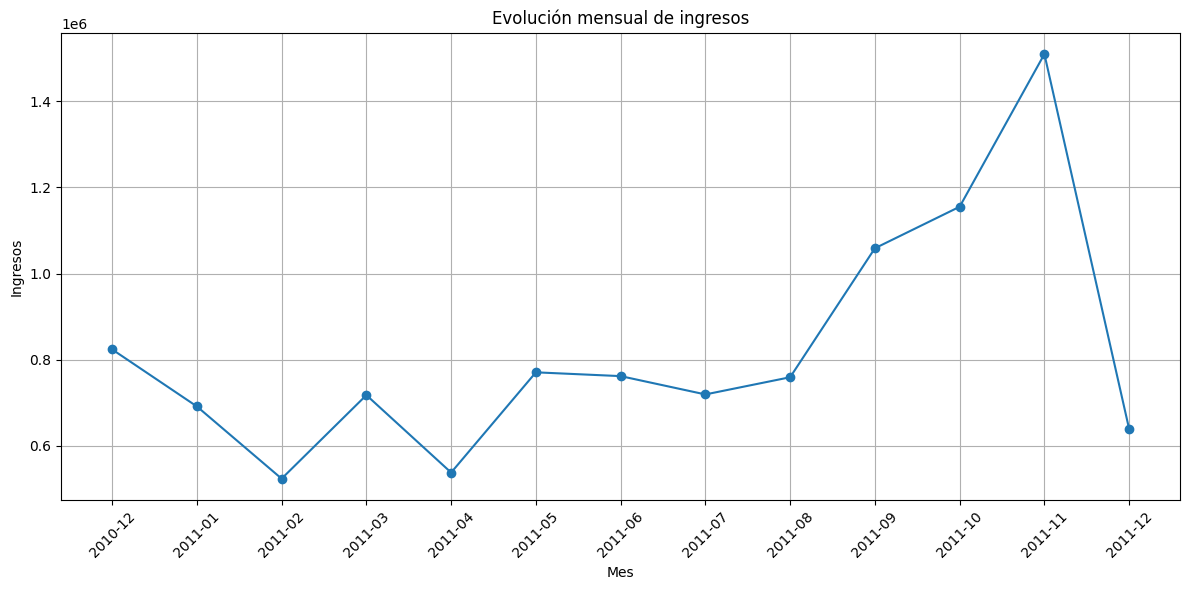

In [43]:
# ============================================================
# 28. Gráfico de ingresos mensuales
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    ventas_mensuales_analisis["year_month"],
    ventas_mensuales_analisis["revenue"],
    marker="o"
)

plt.title("Evolución mensual de ingresos")
plt.xlabel("Mes")
plt.ylabel("Ingresos")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("/content/figures/01_ingresos_mensuales.png", dpi=300)
plt.show()

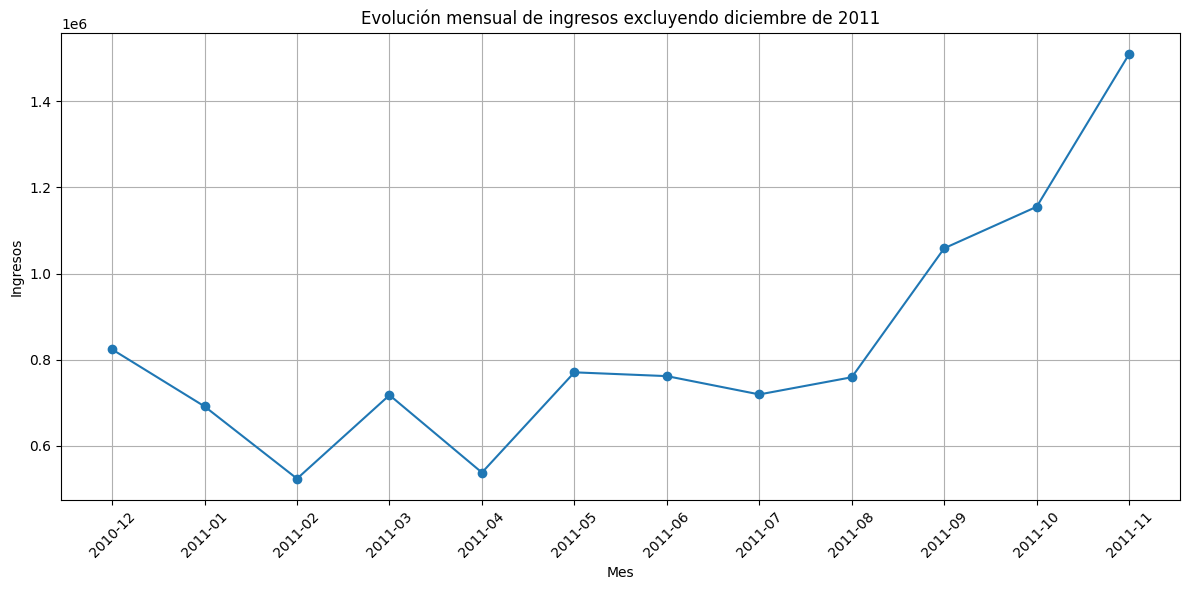

In [44]:
# ============================================================
# 29. Gráfico de ingresos mensuales excluyendo mes parcial
# ============================================================

ventas_mensuales_completas = ventas_mensuales_analisis[
    ventas_mensuales_analisis["year_month"] != "2011-12"
].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    ventas_mensuales_completas["year_month"],
    ventas_mensuales_completas["revenue"],
    marker="o"
)

plt.title("Evolución mensual de ingresos excluyendo diciembre de 2011")
plt.xlabel("Mes")
plt.ylabel("Ingresos")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("/content/figures/02_ingresos_mensuales_sin_mes_parcial.png", dpi=300)
plt.show()

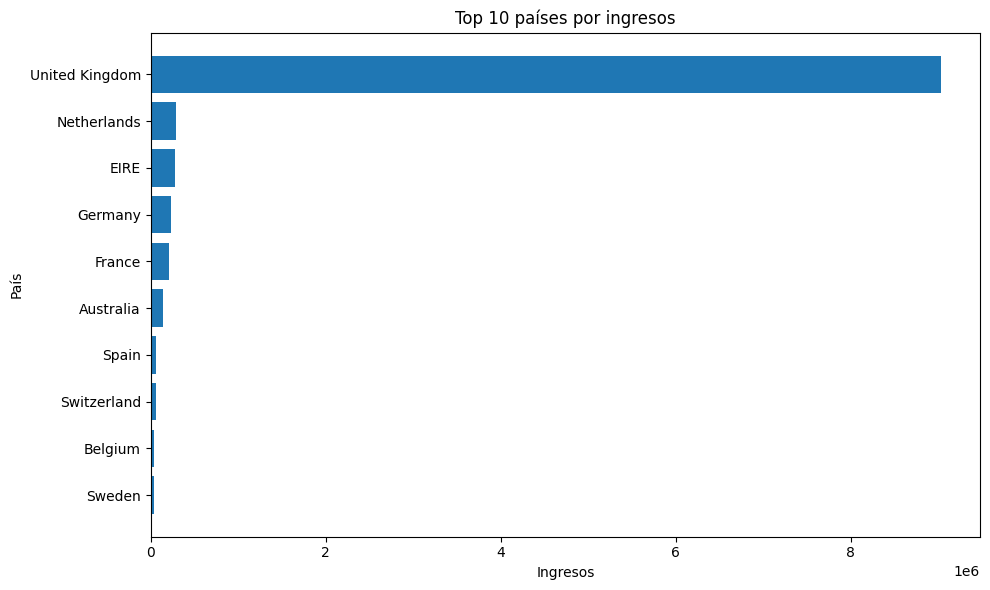

In [45]:
# ============================================================
# 30. Gráfico top 10 países por ingresos
# ============================================================

top_10_paises = ventas_por_pais_analisis.head(10).sort_values("revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_paises["Country"],
    top_10_paises["revenue"]
)

plt.title("Top 10 países por ingresos")
plt.xlabel("Ingresos")
plt.ylabel("País")
plt.tight_layout()

plt.savefig("/content/figures/03_top_10_paises_ingresos.png", dpi=300)
plt.show()

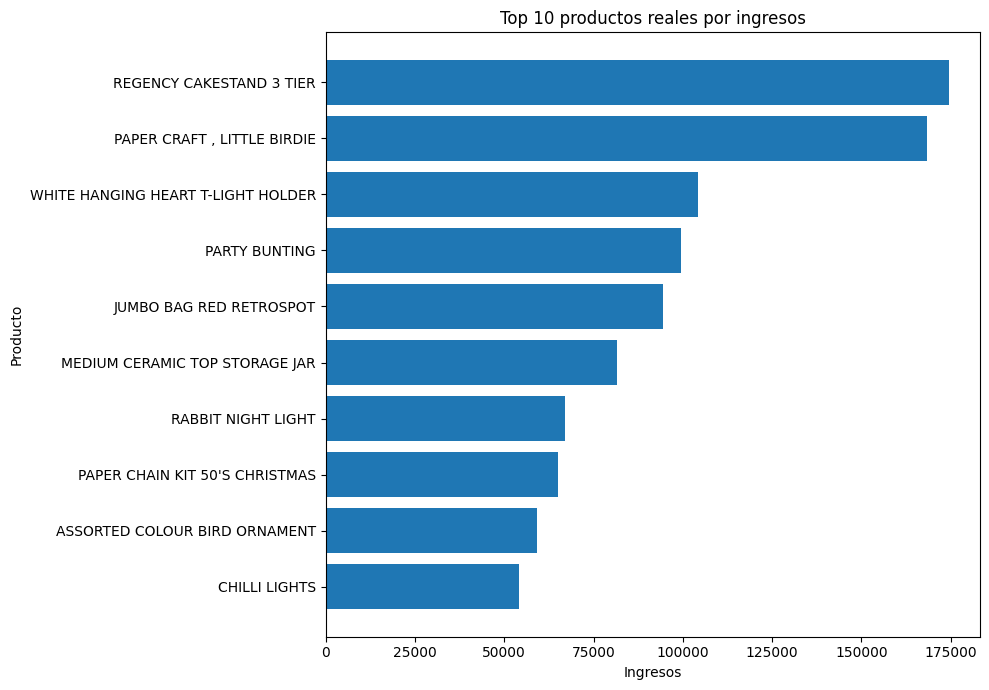

In [46]:
# ============================================================
# 31. Gráfico top 10 productos reales por ingresos
# ============================================================

top_10_productos = top_productos_reales.head(10).sort_values("revenue")

plt.figure(figsize=(10, 7))

plt.barh(
    top_10_productos["Description"],
    top_10_productos["revenue"]
)

plt.title("Top 10 productos reales por ingresos")
plt.xlabel("Ingresos")
plt.ylabel("Producto")
plt.tight_layout()

plt.savefig("/content/figures/04_top_10_productos_reales.png", dpi=300)
plt.show()

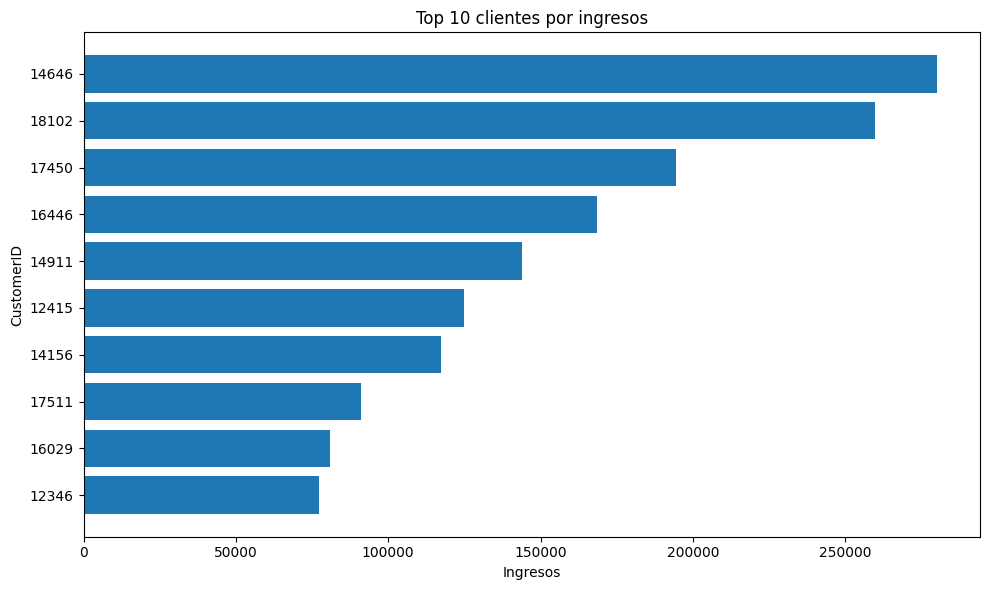

In [47]:
# ============================================================
# 32. Gráfico top 10 clientes por ingresos
# ============================================================

top_10_clientes = top_clientes.head(10).copy()
top_10_clientes["CustomerID"] = top_10_clientes["CustomerID"].astype(str)

top_10_clientes = top_10_clientes.sort_values("revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_clientes["CustomerID"],
    top_10_clientes["revenue"]
)

plt.title("Top 10 clientes por ingresos")
plt.xlabel("Ingresos")
plt.ylabel("CustomerID")
plt.tight_layout()

plt.savefig("/content/figures/05_top_10_clientes_ingresos.png", dpi=300)
plt.show()

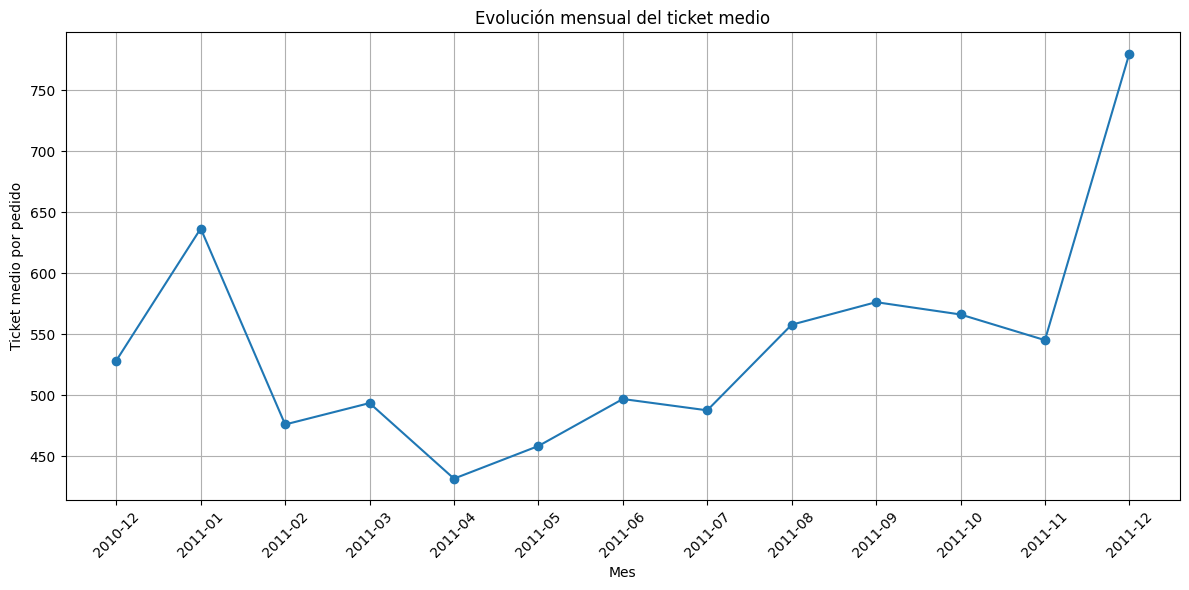

In [48]:
# ============================================================
# 33. Gráfico de ticket medio mensual
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    ventas_mensuales_analisis["year_month"],
    ventas_mensuales_analisis["avg_order_value"],
    marker="o"
)

plt.title("Evolución mensual del ticket medio")
plt.xlabel("Mes")
plt.ylabel("Ticket medio por pedido")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("/content/figures/06_ticket_medio_mensual.png", dpi=300)
plt.show()

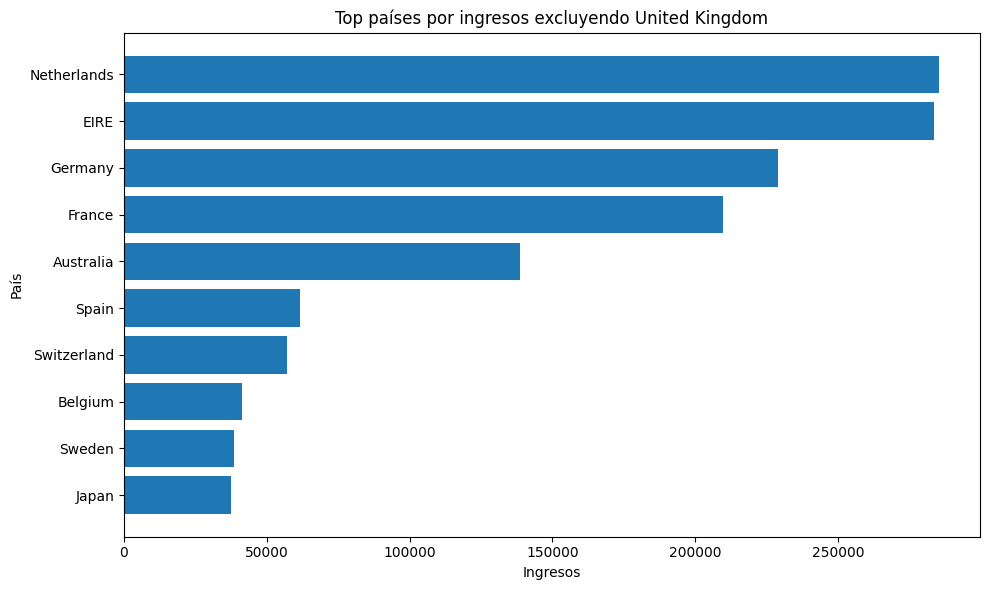

In [49]:
# ============================================================
# 34. Gráfico top países por ingresos excluyendo United Kingdom
# ============================================================

paises_sin_uk = ventas_por_pais_analisis[
    ventas_por_pais_analisis["Country"] != "United Kingdom"
].head(10).sort_values("revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    paises_sin_uk["Country"],
    paises_sin_uk["revenue"]
)

plt.title("Top países por ingresos excluyendo United Kingdom")
plt.xlabel("Ingresos")
plt.ylabel("País")
plt.tight_layout()

plt.savefig("/content/figures/07_top_paises_sin_uk.png", dpi=300)
plt.show()

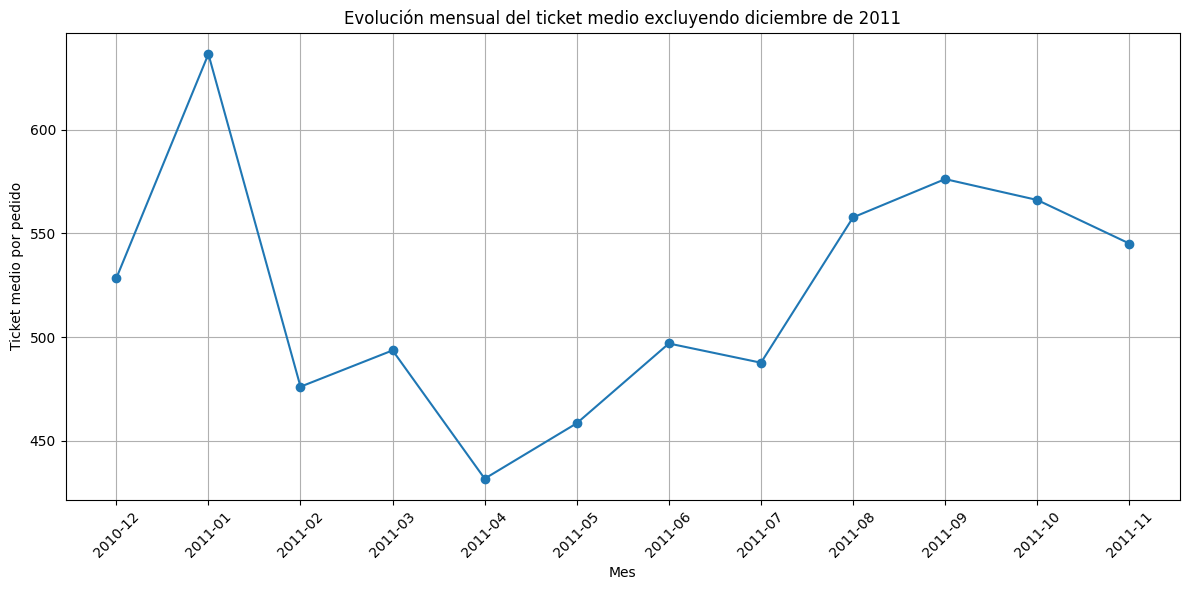

In [50]:
# ============================================================
# 35. Gráfico de ticket medio mensual excluyendo diciembre 2011
# ============================================================

ticket_mensual_completo = ventas_mensuales_analisis[
    ventas_mensuales_analisis["year_month"] != "2011-12"
].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    ticket_mensual_completo["year_month"],
    ticket_mensual_completo["avg_order_value"],
    marker="o"
)

plt.title("Evolución mensual del ticket medio excluyendo diciembre de 2011")
plt.xlabel("Mes")
plt.ylabel("Ticket medio por pedido")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("/content/figures/08_ticket_medio_sin_mes_parcial.png", dpi=300)
plt.show()

In [51]:
# ============================================================
# 36. Resumen ejecutivo de hallazgos principales
# ============================================================

total_revenue_val = kpis_generales.loc[0, "total_revenue"]
total_orders_val = kpis_generales.loc[0, "total_orders"]
total_customers_val = kpis_generales.loc[0, "total_customers"]
avg_order_value_val = kpis_generales.loc[0, "avg_order_value"]

pais_principal = ventas_por_pais_analisis.iloc[0]["Country"]
pais_principal_pct = ventas_por_pais_analisis.iloc[0]["revenue_share_pct"]

producto_principal = top_productos_reales.iloc[0]["Description"]
producto_principal_revenue = top_productos_reales.iloc[0]["revenue"]

cliente_principal = top_clientes.iloc[0]["CustomerID"]
cliente_principal_revenue = top_clientes.iloc[0]["revenue"]

mejor_mes = ventas_mensuales_analisis[
    ventas_mensuales_analisis["year_month"] != "2011-12"
].sort_values("revenue", ascending=False).iloc[0]

hallazgos = pd.DataFrame({
    "area": [
        "Ingresos generales",
        "Pedidos",
        "Clientes",
        "Concentración geográfica",
        "Producto principal",
        "Cliente principal",
        "Mejor mes completo",
        "Advertencia metodológica"
    ],
    "hallazgo": [
        f"El negocio generó {total_revenue_val:,.2f} en ingresos tras la limpieza.",
        f"Se identificaron {total_orders_val:,} pedidos únicos.",
        f"Se identificaron {total_customers_val:,} clientes únicos.",
        f"{pais_principal} concentra el {pais_principal_pct}% de los ingresos.",
        f"El producto real con más ingresos es {producto_principal}, con {producto_principal_revenue:,.2f}.",
        f"El cliente con mayor facturación es {cliente_principal}, con {cliente_principal_revenue:,.2f}.",
        f"El mejor mes completo fue {mejor_mes['year_month']}, con {mejor_mes['revenue']:,.2f} en ingresos.",
        "Diciembre de 2011 se interpreta con cautela porque parece ser un mes incompleto."
    ]
})

display(hallazgos)

,area,hallazgo
0,Ingresos generales,"El negocio generó 10,666,684.54 en ingresos tr..."
1,Pedidos,"Se identificaron 19,960 pedidos únicos."
2,Clientes,"Se identificaron 4,338 clientes únicos."
3,Concentración geográfica,United Kingdom concentra el 84.61% de los ingr...
4,Producto principal,El producto real con más ingresos es REGENCY C...
5,Cliente principal,"El cliente con mayor facturación es 14646, con..."
6,Mejor mes completo,"El mejor mes completo fue 2011-11, con 1,509,4..."
7,Advertencia metodológica,Diciembre de 2011 se interpreta con cautela po...


In [52]:
# ============================================================
# 37. Exportar resumen de hallazgos
# ============================================================

hallazgos.to_csv("/content/data/processed/hallazgos_ejecutivos.csv", index=False)

print("Archivo hallazgos_ejecutivos.csv exportado correctamente.")

Archivo hallazgos_ejecutivos.csv exportado correctamente.


In [53]:
# ============================================================
# 38. Visualización completa de hallazgos ejecutivos
# ============================================================

pd.set_option("display.max_colwidth", None)

display(hallazgos)

,area,hallazgo
0,Ingresos generales,"El negocio generó 10,666,684.54 en ingresos tras la limpieza."
1,Pedidos,"Se identificaron 19,960 pedidos únicos."
2,Clientes,"Se identificaron 4,338 clientes únicos."
3,Concentración geográfica,United Kingdom concentra el 84.61% de los ingresos.
4,Producto principal,"El producto real con más ingresos es REGENCY CAKESTAND 3 TIER, con 174,484.74."
5,Cliente principal,"El cliente con mayor facturación es 14646, con 280,206.02."
6,Mejor mes completo,"El mejor mes completo fue 2011-11, con 1,509,496.33 en ingresos."
7,Advertencia metodológica,Diciembre de 2011 se interpreta con cautela porque parece ser un mes incompleto.


In [54]:
# ============================================================
# 39. Conclusiones profesionales del análisis
# ============================================================

conclusiones = """
# Conclusiones del análisis

## 1. Visión general del negocio

Tras el proceso de limpieza, el dataset analizado contiene ventas válidas por un importe total de 10.666.684,54.
Se identificaron 19.960 pedidos únicos, 4.338 clientes únicos, 3.922 productos diferentes y ventas en 38 países.

El ticket medio por pedido fue de 534,40, lo que indica que la empresa no trabaja únicamente con compras pequeñas,
sino que también existen pedidos de importe considerable.

## 2. Concentración geográfica

El análisis por país muestra una fuerte concentración del negocio en United Kingdom, que representa el 84,61%
de los ingresos totales. Esto indica que la empresa depende principalmente del mercado británico.

Aunque existen ventas internacionales, el peso del resto de países es mucho menor. Después de United Kingdom,
los mercados más relevantes son Netherlands, EIRE, Germany y France.

Desde una perspectiva de negocio, esta concentración puede ser positiva si el mercado principal es sólido,
pero también supone un riesgo: cualquier caída en United Kingdom afectaría de forma importante a los ingresos globales.

## 3. Mercados internacionales

Al excluir United Kingdom, se observa que Netherlands y EIRE son los países internacionales con mayor facturación.
Germany y France también presentan un volumen relevante.

Esto sugiere que la empresa podría analizar oportunidades de crecimiento internacional, especialmente en los países
que ya muestran tracción comercial.

## 4. Productos principales

El ranking de productos fue corregido para excluir conceptos administrativos como POSTAGE, DOTCOM POSTAGE, Manual
o BANK CHARGES. Esta decisión mejora la calidad del análisis, ya que evita considerar gastos, ajustes o conceptos
internos como si fueran productos reales.

Tras esta limpieza específica, los productos con mayor facturación son REGENCY CAKESTAND 3 TIER, PAPER CRAFT,
LITTLE BIRDIE, WHITE HANGING HEART T-LIGHT HOLDER, PARTY BUNTING y JUMBO BAG RED RETROSPOT.

Estos productos deberían recibir atención comercial prioritaria, ya que generan una parte importante de los ingresos.

## 5. Clientes de alto valor

El análisis de clientes muestra que algunos clientes concentran importes de compra muy superiores a la media.
El cliente 14646 es el cliente con mayor facturación del dataset.

Desde una perspectiva de negocio, sería recomendable crear estrategias de fidelización para estos clientes de alto valor,
ya que su pérdida podría tener un impacto significativo en los ingresos.

## 6. Evolución mensual

La evolución mensual muestra un crecimiento destacado durante los últimos meses completos de 2011, especialmente
entre septiembre y noviembre. El mejor mes completo fue noviembre de 2011.

Diciembre de 2011 debe interpretarse con cautela porque parece ser un mes incompleto en el dataset. Por ese motivo,
se creó también un gráfico excluyendo diciembre de 2011 para evitar conclusiones erróneas sobre una posible caída
de ingresos.

## 7. Recomendaciones de negocio

A partir del análisis realizado, se proponen las siguientes recomendaciones:

1. Proteger y reforzar el mercado principal de United Kingdom, ya que concentra la mayor parte de los ingresos.
2. Analizar oportunidades de expansión en Netherlands, EIRE, Germany y France.
3. Priorizar los productos con mayor facturación en campañas comerciales, stock y visibilidad.
4. Diseñar acciones de fidelización para clientes de alto valor.
5. Monitorizar mensualmente ingresos, pedidos, ticket medio y concentración geográfica mediante un dashboard.
6. Revisar periódicamente conceptos administrativos para no mezclarlos con productos reales en los análisis.

## 8. Limitaciones del análisis

El dataset contiene operaciones históricas de un periodo concreto y no incluye información adicional sobre márgenes,
costes, campañas de marketing, canales de adquisición o stock disponible.

Además, el mes de diciembre de 2011 parece incompleto, por lo que no debe compararse directamente con meses completos.
"""

print(conclusiones)


# Conclusiones del análisis

## 1. Visión general del negocio

Tras el proceso de limpieza, el dataset analizado contiene ventas válidas por un importe total de 10.666.684,54. 
Se identificaron 19.960 pedidos únicos, 4.338 clientes únicos, 3.922 productos diferentes y ventas en 38 países.

El ticket medio por pedido fue de 534,40, lo que indica que la empresa no trabaja únicamente con compras pequeñas, 
sino que también existen pedidos de importe considerable.

## 2. Concentración geográfica

El análisis por país muestra una fuerte concentración del negocio en United Kingdom, que representa el 84,61% 
de los ingresos totales. Esto indica que la empresa depende principalmente del mercado británico.

Aunque existen ventas internacionales, el peso del resto de países es mucho menor. Después de United Kingdom, 
los mercados más relevantes son Netherlands, EIRE, Germany y France.

Desde una perspectiva de negocio, esta concentración puede ser positiva si el mercado principal es sólido, 
pe

In [55]:
# ============================================================
# 40. Exportar conclusiones en archivo Markdown
# ============================================================

with open("/content/data/processed/conclusiones_analisis.md", "w", encoding="utf-8") as f:
    f.write(conclusiones)

print("Archivo conclusiones_analisis.md exportado correctamente.")

Archivo conclusiones_analisis.md exportado correctamente.


# Conclusiones del análisis

## 1. Visión general del negocio

Tras el proceso de limpieza, el dataset analizado contiene ventas válidas por un importe total de **10.666.684,54**.  
Se identificaron **19.960 pedidos únicos**, **4.338 clientes únicos**, **3.922 productos diferentes** y ventas en **38 países**.

El ticket medio por pedido fue de **534,40**, lo que indica que la empresa no trabaja únicamente con compras pequeñas, sino que también existen pedidos de importe considerable.

## 2. Concentración geográfica

El análisis por país muestra una fuerte concentración del negocio en **United Kingdom**, que representa el **84,61%** de los ingresos totales.

Aunque existen ventas internacionales, el peso del resto de países es mucho menor. Después de United Kingdom, los mercados más relevantes son **Netherlands, EIRE, Germany y France**.

Desde una perspectiva de negocio, esta concentración puede ser positiva si el mercado principal es sólido, pero también supone un riesgo: cualquier caída en United Kingdom afectaría de forma importante a los ingresos globales.

## 3. Productos principales

El ranking de productos fue corregido para excluir conceptos administrativos como `POSTAGE`, `DOTCOM POSTAGE`, `Manual` o `BANK CHARGES`. Esta decisión mejora la calidad del análisis, ya que evita considerar gastos, ajustes o conceptos internos como si fueran productos reales.

Tras esta limpieza específica, los productos con mayor facturación son:

- `REGENCY CAKESTAND 3 TIER`
- `PAPER CRAFT , LITTLE BIRDIE`
- `WHITE HANGING HEART T-LIGHT HOLDER`
- `PARTY BUNTING`
- `JUMBO BAG RED RETROSPOT`

## 4. Clientes de alto valor

El análisis de clientes muestra que algunos clientes concentran importes de compra muy superiores a la media. El cliente **14646** es el cliente con mayor facturación del dataset.

Desde una perspectiva de negocio, sería recomendable crear estrategias de fidelización para estos clientes de alto valor, ya que su pérdida podría tener un impacto significativo en los ingresos.

## 5. Evolución mensual

La evolución mensual muestra un crecimiento destacado durante los últimos meses completos de 2011, especialmente entre septiembre y noviembre. El mejor mes completo fue **noviembre de 2011**.

Diciembre de 2011 debe interpretarse con cautela porque parece ser un mes incompleto en el dataset. Por ese motivo, se creó también un gráfico excluyendo diciembre de 2011 para evitar conclusiones erróneas sobre una posible caída de ingresos.

## 6. Recomendaciones de negocio

A partir del análisis realizado, se proponen las siguientes recomendaciones:

1. Proteger y reforzar el mercado principal de United Kingdom.
2. Analizar oportunidades de expansión en Netherlands, EIRE, Germany y France.
3. Priorizar los productos con mayor facturación en campañas comerciales, stock y visibilidad.
4. Diseñar acciones de fidelización para clientes de alto valor.
5. Monitorizar mensualmente ingresos, pedidos, ticket medio y concentración geográfica mediante un dashboard.
6. Separar conceptos administrativos de productos reales en futuros análisis.

## 7. Limitaciones del análisis

El dataset contiene operaciones históricas de un periodo concreto y no incluye información adicional sobre márgenes, costes, campañas de marketing, canales de adquisición o stock disponible.

Además, el mes de diciembre de 2011 parece incompleto, por lo que no debe compararse directamente con meses completos.

In [56]:
# ============================================================
# 41. Crear estructura final del proyecto para portfolio
# ============================================================

import os

project_root = "/content/revenue-command-center-ecommerce"

folders = [
    "data/processed",
    "sql",
    "figures",
    "reports",
    "dashboard"
]

for folder in folders:
    os.makedirs(os.path.join(project_root, folder), exist_ok=True)

print("Estructura del proyecto creada correctamente:")
for folder in folders:
    print("-", os.path.join(project_root, folder))

Estructura del proyecto creada correctamente:
- /content/revenue-command-center-ecommerce/data/processed
- /content/revenue-command-center-ecommerce/sql
- /content/revenue-command-center-ecommerce/figures
- /content/revenue-command-center-ecommerce/reports
- /content/revenue-command-center-ecommerce/dashboard


In [57]:
# ============================================================
# 42. Copiar archivos generados al proyecto final
# ============================================================

import shutil
import glob

# Copiar CSV procesados
for file in glob.glob("/content/data/processed/*"):
    shutil.copy(file, os.path.join(project_root, "data/processed"))

# Copiar gráficos
for file in glob.glob("/content/figures/*"):
    shutil.copy(file, os.path.join(project_root, "figures"))

print("CSV y gráficos copiados correctamente al proyecto final.")

CSV y gráficos copiados correctamente al proyecto final.


In [58]:
# ============================================================
# 43. Crear scripts SQL del proyecto
# ============================================================

sql_scripts = {
    "01_kpis_generales.sql": """
SELECT
    ROUND(SUM("Revenue"), 2) AS total_revenue,
    COUNT(DISTINCT "InvoiceNo") AS total_orders,
    COUNT(DISTINCT "CustomerID") AS total_customers,
    COUNT(DISTINCT "StockCode") AS total_products,
    COUNT(DISTINCT "Country") AS total_countries,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value,
    ROUND(SUM("Quantity") * 1.0 / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_units_per_order
FROM sales;
""",

    "02_ventas_por_pais.sql": """
SELECT
    "Country",
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    COUNT(DISTINCT "CustomerID") AS customers,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM sales
GROUP BY "Country"
ORDER BY revenue DESC;
""",

    "03_top_productos_reales.sql": """
SELECT
    "StockCode",
    "Description",
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_revenue_per_order
FROM real_products
GROUP BY "StockCode", "Description"
ORDER BY revenue DESC
LIMIT 20;
""",

    "04_top_clientes.sql": """
SELECT
    "CustomerID",
    "Country",
    COUNT(DISTINCT "InvoiceNo") AS orders,
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue"), 2) AS revenue,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM customers
GROUP BY "CustomerID", "Country"
ORDER BY revenue DESC
LIMIT 20;
""",

    "05_ventas_mensuales.sql": """
SELECT
    "year_month",
    ROUND(SUM("Revenue"), 2) AS revenue,
    COUNT(DISTINCT "InvoiceNo") AS orders,
    COUNT(DISTINCT "CustomerID") AS customers,
    SUM("Quantity") AS total_units,
    ROUND(SUM("Revenue") / COUNT(DISTINCT "InvoiceNo"), 2) AS avg_order_value
FROM sales
GROUP BY "year_month"
ORDER BY "year_month";
"""
}

for filename, content in sql_scripts.items():
    path = os.path.join(project_root, "sql", filename)
    with open(path, "w", encoding="utf-8") as f:
        f.write(content.strip())

print("Scripts SQL creados correctamente.")

Scripts SQL creados correctamente.


In [60]:
# ============================================================
# 44. Crear README.md profesional
# ============================================================

readme = """
# Revenue Command Center para e-commerce

## Objetivo del proyecto

Este proyecto analiza un dataset de ventas online con el objetivo de construir un cuadro de mando comercial para entender ingresos, pedidos, clientes, productos principales, países relevantes y evolución mensual del negocio.

El enfoque simula un caso real de trabajo de Data Analyst / BI Analyst, combinando Python, SQL, limpieza de datos, análisis exploratorio, KPIs, visualizaciones y conclusiones de negocio.

## Dataset

Dataset utilizado: Online Retail Dataset.

El dataset contiene operaciones de una tienda online, incluyendo información de facturas, productos, cantidades, fechas, precios, clientes y países.

Columnas principales:

- InvoiceNo
- StockCode
- Description
- Quantity
- InvoiceDate
- UnitPrice
- CustomerID
- Country

## Stack utilizado

- Python
- Pandas
- DuckDB
- SQL
- Matplotlib
- Google Colab
- CSV para dashboard
- Looker Studio / Power BI como herramienta final de visualización

## Proceso realizado

1. Carga del dataset.
2. Exploración inicial de columnas, tipos de datos y valores nulos.
3. Detección de cancelaciones, cantidades negativas y precios no válidos.
4. Limpieza del dataset.
5. Creación de columna Revenue.
6. Separación entre ventas generales y ventas con cliente identificado.
7. Registro de tablas en DuckDB.
8. Creación de consultas SQL para KPIs.
9. Análisis de ventas por país, producto, cliente y mes.
10. Exclusión de conceptos administrativos del ranking de productos.
11. Creación de gráficos.
12. Generación de hallazgos ejecutivos.

## KPIs principales

- Ingresos totales: 10.666.684,54
- Pedidos únicos: 19.960
- Clientes únicos: 4.338
- Productos únicos: 3.922
- Países con ventas: 38
- Ticket medio por pedido: 534,40

## Hallazgos principales

1. United Kingdom concentra el 84,61% de los ingresos.
2. Netherlands, EIRE, Germany y France son los mercados internacionales más relevantes después de United Kingdom.
3. El producto real con mayor facturación es REGENCY CAKESTAND 3 TIER.
4. El cliente 14646 es el cliente con mayor facturación.
5. Noviembre de 2011 fue el mejor mes completo del periodo analizado.
6. Diciembre de 2011 debe interpretarse con cautela porque parece ser un mes incompleto.

## Recomendaciones de negocio

- Reforzar el mercado principal de United Kingdom.
- Analizar oportunidades de expansión en Netherlands, EIRE, Germany y France.
- Priorizar productos de alta facturación en campañas, stock y visibilidad.
- Diseñar acciones de fidelización para clientes de alto valor.
- Monitorizar mensualmente ingresos, pedidos, ticket medio y concentración geográfica.
- Separar conceptos administrativos de productos reales en futuros análisis.

## Limitaciones

El dataset no incluye costes, márgenes, campañas de marketing, canales de adquisición ni información de stock. Además, diciembre de 2011 parece incompleto, por lo que no debe compararse directamente con meses completos.

## Estructura del repositorio

revenue-command-center-ecommerce/
- data/processed/
- sql/
- figures/
- reports/
- dashboard/
- README.md

## Autor

Proyecto realizado por Juan Carlos como parte de su portfolio de ciencia de datos orientado a roles de Data Analyst / BI Analyst.
"""

with open(os.path.join(project_root, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme.strip())

print("README.md creado correctamente.")

README.md creado correctamente.


In [62]:
# ============================================================
# 45. Crear requirements.txt
# ============================================================

requirements = """
pandas
numpy
duckdb
openpyxl
matplotlib
"""

with open(os.path.join(project_root, "requirements.txt"), "w", encoding="utf-8") as f:
    f.write(requirements.strip())

print("requirements.txt creado correctamente.")

requirements.txt creado correctamente.


In [63]:
# ============================================================
# 46. Crear ZIP descargable del proyecto
# ============================================================

shutil.make_archive(
    base_name="/content/revenue-command-center-ecommerce",
    format="zip",
    root_dir=project_root
)

print("ZIP creado correctamente:")
print("/content/revenue-command-center-ecommerce.zip")

ZIP creado correctamente:
/content/revenue-command-center-ecommerce.zip


In [64]:
# ============================================================
# 47. Descargar ZIP del proyecto
# ============================================================

from google.colab import files

files.download("/content/revenue-command-center-ecommerce.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>